In [ ]:
# This program intentionally includes incorrect code for group work purposes.
# Please do not use this outside of the group work context.

In [ ]:
# Import necessary libraries.
from pandas import read_csv
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

In [ ]:
df = read_csv("CHEMATE114_11_group_work.csv")

In [ ]:
df = df.dropna() #drop missing values

In [ ]:
df

,density,formation_energy_per_atom,band_gap,is_metal
0,2.324438,0.101697,0.0,True
1,2.439748,0.202360,0.0,True
2,2.193120,0.108455,0.0,True
3,2.172323,0.129124,0.0,True
4,2.322183,0.128775,0.0,True
...,...,...,...,...
5461,4.213434,-0.407545,0.0,True
5462,6.585561,-0.331478,0.0,True
5463,7.851462,-0.615634,0.0,True
5464,5.707623,-0.388405,0.0,True


In [ ]:
df.describe() #summarizes numeric data

,density,formation_energy_per_atom,band_gap
count,5465.000000,5465.000000,5465.000000
mean,5.374342,-0.864999,0.754051
std,3.113429,1.147789,1.650876
min,0.102754,-3.863396,0.000000
25%,2.483916,-1.055389,0.000000
50%,4.921402,-0.600702,0.000000
75%,7.489241,-0.199792,0.056600
max,18.208518,4.143176,8.084400


In [ ]:
df_x = df.drop(columns=['band_gap'])
df_y = df['band_gap']

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(df_x, df_y, test_size=0.2, random_state=42)

In [ ]:
# Normalize input data
# Setup the scaling tool.
scaler = MinMaxScaler()
# Fit the scaler on the training data.
x_train_scaled = scaler.fit_transform(x_train)
# Transform the testing data using the fitted scaler.
x_test_scaled = scaler.transform(x_test)

In [ ]:
# This is to use the fixed initial parameters in the DL model.
tf.keras.utils.set_random_seed(42)

In [ ]:
x_train_scaled.shape

(4372, 3)

In [ ]:
# Create your own deep learning model.
model = Sequential()
model.add(Input(shape=(3,)))
model.add(Dense(100,activation='relu'))
model.add(Dense(70,activation='relu'))
model.add(Dense(8,activation='relu'))
model.add(Dense(1,activation='relu'))

In [ ]:
# Compile the model.
model.compile(loss='mae', optimizer='adam', metrics=['mae'])

In [ ]:
# Train the model
model.fit(x_train_scaled, y_train, epochs=100)

Epoch 1/100
137/137 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2219 - mae: 0.2219
Epoch 2/100
137/137 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2228 - mae: 0.2228
Epoch 3/100
137/137 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2214 - mae: 0.2214
Epoch 4/100
137/137 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2211 - mae: 0.2211
Epoch 5/100
137/137 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2221 - mae: 0.2221
Epoch 6/100
137/137 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2220 - mae: 0.2220
Epoch 7/100
137/137 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2215 - mae: 0.2215
Epoch 8/100
137/137 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2209 - mae: 0.2209
Epoch 9/100
137/137 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2209 - mae: 0.2209
Epoch 10/100
137/137 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2209 - mae: 0.2209
Epoch 11/100
137/137 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2207 - mae: 0.2207
Epoch 12/100
137/137 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2210 - mae: 0.2210
Epoch 13/100


In [ ]:
# Make predictions with the test set.
y_predict = model.predict(x_test_scaled)

35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


In [ ]:
# model performance/calculate mean absolute error
mae = mean_absolute_error(y_test, y_predict)
print(f'MAE: {mae}')

MAE: 0.24666922162630533


In [ ]:
y_predict.min(), y_predict.max()

(np.float32(0.0), np.float32(6.1886244))

In [ ]:
y_test.min(), y_test.max()

(0.0, 8.0844)

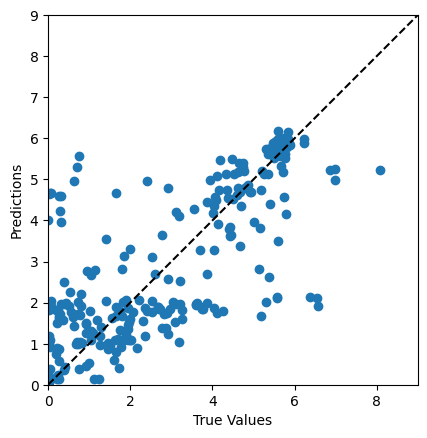

In [ ]:
# Visualize the model performance.
plt.scatter(y_test,y_predict)
plt.xlabel('True Values')
plt.xlim(0,9)
plt.ylim(0,9)
plt.gca().set_aspect('equal')
plt.ylabel('Predictions')
plt.plot([0, 9], [0, 9], 'k--', label='y=x')
plt.show()